# SocialChoice-05 : Gibbard-Satterthwaite sans mystere - la manipulation comme temoin

**Navigation** : [<< 04-Computational-Aggregation](ChoixSocial-04-Computational-Aggregation-SAT-Z3-CSharp.ipynb) | [Index](README.md) | [voisinage geometrique : 03f-Deux-Especes-de-Fleches](../GameTheory-03d-Deux-Especes-de-Fleches-CSharp.ipynb)

## Le temoin d'exploitation

Une regle de vote est **manipulable** s'il existe un profil de preferences et un electeur qui peut soumettre un bulletin **insincere** obtenant un resultat qu'il prefere au resultat sincere. Gibbard (1973) et Satterthwaite (1975) ont prouve que pour **toute regle surjective et non dictatoriale** sur au moins 3 alternatives (preferences lineaires strictes), il **existe** un profil manipulable — le theoreme ne dit pas que tout profil l'est.

La consequence epistemologique est importante : le bulletin insincere est un **temoin** d'exploitation. Quand un electeur ment, il exhibe un bulletin et un vainqueur qui n'aurait pas existe avec un bulletin sincere - et la preuve d'exploitation est constructive. C'est le noyau mathematique propre de ce que Arrow designait comme l'impossibilite d'eviter la strategie sans tomber dans la dictature.

Trois parties, chacune composee d'un exemple guide resolu et d'un exercice a completer :
1. **Une election concrete** - 3 votants, 3 candidats, regle Pluralite. Exemple guide : le vainqueur sincere et sa sensibilite au tiebreak. Exercice : construire un profil a 4 votants ou le tiebreak decide.
2. **Le temoin** - identifier le bulletin insincere qui ameliore le sort d'un electeur. Exemple guide : exhiber le temoin (bulletin + vainqueur + gain). Exercice : generaliser la recherche a un nombre quelconque de votants.
3. **Comparer les regles** - Pluralite vs Borda : meme profil, meme temoin ? Exemple guide : mesurer le cout de la recherche de manipulation. Exercice : trouver un profil a 3 votants ou Borda est manipulable.

Le profil canonique est celui de Satterthwaite (1975), section 4 : 3 votants, preferences lineaires strictes, 3 alternatives. La manipulation existe mais elle est **fragile** (depend du tiebreak). C'est cette fragilite qui rend le theoreme contre-intuitif : on pourrait croire que la manipulation est rare. Elle est structurellement toujours presente.

## 1. Le modele : 3 votants, 3 candidats, regles usuelles

On considere un corps electoral de 3 votants qui doivent choisir parmi 3 alternatives `A, B, C`. Chaque votant `i` a des preferences lineaires strictes (un ordre total sans ex-aequo) sur les alternatives.

**Regles de vote** :
- **Pluralite** : chaque electeur vote pour son candidat prefere. Le candidat avec le plus de voix gagne. En cas d'egalite, on applique un tiebreak lexicographique (`A > B > C`).
- **Borda** : chaque electeur etablit un classement. Le candidat au rang 1 recoit 2 points, rang 2 recoit 1 point, rang 3 recoit 0. Le candidat avec le plus de points gagne.

**Manipulation** : un electeur `i` peut soumettre un bulletin `b'` different de son vrai classement `b` si `regle(b, b_-i, b')` est strictement prefere a `regle(b, b_-i, b)`. Si un tel bulletin existe, l'electeur a interet a mentir, et la regle est **manipulable** sur ce profil.

**Profil canonique (Satterthwaite 1975, variante pedagogique)** :
- V1 : `A > B > C`
- V2 : `B > A > C`
- V3 : `C > B > A`

### Implementation : regles de vote et helpers

In [1]:
using System;
using System.Collections.Generic;
using System.Linq;
using System.Text;
using Microsoft.DotNet.Interactive.Formatting;

record PlotSvg(string Content);

Formatter.Register<PlotSvg>((value, writer) => writer.Write(value.Content), "text/html");
Formatter.Register<PlotSvg>((value, writer) => writer.Write(value.Content), "image/svg+xml");
Formatter.SetPreferredMimeTypesFor(typeof(PlotSvg), "image/svg+xml");

static class SocialChoice
{
    public static string PluralityWinner(
        IReadOnlyList<List<string>> ballots,
        IReadOnlyList<string>? tiebreak = null)
    {
        var order = tiebreak ?? new List<string> { "A", "B", "C" };
        var scores = order.ToDictionary(candidate => candidate, candidate => 0);

        foreach (var ballot in ballots)
        {
            scores[ballot[0]]++;
        }

        return order
            .OrderByDescending(candidate => scores[candidate])
            .ThenBy(candidate => order.ToList().IndexOf(candidate))
            .First();
    }

    public static string BordaWinner(IReadOnlyList<List<string>> ballots)
    {
        var scores = new Dictionary<string, int>
        {
            ["A"] = 0,
            ["B"] = 0,
            ["C"] = 0
        };

        foreach (var ballot in ballots)
        {
            for (var rank = 0; rank < ballot.Count; rank++)
            {
                scores[ballot[rank]] += 2 - rank;
            }
        }

        return scores
            .OrderByDescending(entry => entry.Value)
            .ThenBy(entry => entry.Key, StringComparer.Ordinal)
            .First()
            .Key;
    }

    public static int RankOf(string alternative, IReadOnlyList<string> preference)
    {
        return preference.ToList().IndexOf(alternative) + 1;
    }
}

string SvgText(string value) => System.Net.WebUtility.HtmlEncode(value);

// Profil canonique (Satterthwaite 1975, simplifie)
var PROFILE = new List<List<string>>
{
    new() { "A", "B", "C" }, // V1 : A en tete
    new() { "B", "A", "C" }, // V2 : B en tete
    new() { "C", "B", "A" } // V3 : C en tete (peaks opposes a V1)
};

// Sanity check
var sincere = PROFILE.Select(preference => new List<string>(preference)).ToList();
Console.WriteLine($"Profil : V1={string.Join(", ", sincere[0])}, V2={string.Join(", ", sincere[1])}, V3={string.Join(", ", sincere[2])}");
Console.WriteLine($"Vainqueur Pluralite sincere : {SocialChoice.PluralityWinner(sincere)}");
Console.WriteLine($"Vainqueur Borda sincere     : {SocialChoice.BordaWinner(sincere)}");

// Conclusion derivee (PAS de chaine en dur)
var pluralityWinner = SocialChoice.PluralityWinner(sincere);
var bordaWinner = SocialChoice.BordaWinner(sincere);
if (pluralityWinner == bordaWinner)
{
    Console.WriteLine($"  -> Pluralite et Borda donnent toutes deux {pluralityWinner} (coincidence).");
}
else
{
    Console.WriteLine($"  -> Pluralite {pluralityWinner}, Borda {bordaWinner} : divergent.");
}

Console.WriteLine($"     Rang {pluralityWinner} pour V3 : {SocialChoice.RankOf(pluralityWinner, PROFILE[2])}.");
Console.WriteLine($"     Rang de A pour V3 : {SocialChoice.RankOf("A", PROFILE[2])} (dernier)");

Profil : V1=A, B, C, V2=B, A, C, V3=C, B, A


Vainqueur Pluralite sincere : A


Vainqueur Borda sincere     : B


  -> Pluralite A, Borda B : divergent.


     Rang A pour V3 : 3.


     Rang de A pour V3 : 3 (dernier)



(17,30): warning CS8632: L'annotation pour les types référence Nullable doit être utilisée uniquement dans le code au sein d'un contexte d'annotations '#nullable'.



## 2. Exemple guide 1 : L'election concrete sous Pluralite

Sous Pluralite sincere :
- V1 vote A (rang 1)
- V2 vote B (rang 1)
- V3 vote C (rang 1)

Le code ci-dessous calcule le vainqueur sous trois ordres de departage, le vainqueur Borda, puis le rang de A pour chaque votant.

### Question 1 : verifier le resultat sincere et sa fragilite

Pluralite sincere sous 3 tiebreaks :


  Tiebreak A>B>C : vainqueur = A


  Tiebreak B>A>C : vainqueur = B


  Tiebreak C>B>A : vainqueur = C



Borda sincere : vainqueur = B (deterministe, pas de tiebreak)



Rang du vainqueur A (tiebreak A) pour chaque votant :


  V1 (pref A, B, C) : rang de A = 1


  V2 (pref B, A, C) : rang de A = 2


  V3 (pref C, B, A) : rang de A = 3


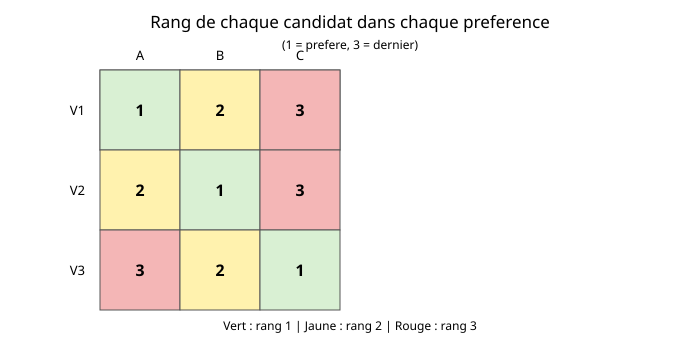


Observation : le vainqueur A est le pire choix pour V3 (rang 3).


C'est cette insatisfaction qui cree l'opportunite de manipulation.


In [2]:
// --- Exemple guide 1 : resultat sincere et sensibilite au tiebreak ---

var sincere = PROFILE.Select(preference => new List<string>(preference)).ToList();

// Pluralite sincere sous chaque tiebreak
Console.WriteLine("Pluralite sincere sous 3 tiebreaks :");
var tiebreaks = new List<List<string>>
{
    new() { "A", "B", "C" },
    new() { "B", "A", "C" },
    new() { "C", "B", "A" }
};

foreach (var tiebreak in tiebreaks)
{
    var winner = SocialChoice.PluralityWinner(sincere, tiebreak);
    Console.WriteLine($"  Tiebreak {string.Join(">", tiebreak)} : vainqueur = {winner}");
}

// Borda sincere
Console.WriteLine($"\nBorda sincere : vainqueur = {SocialChoice.BordaWinner(sincere)} (deterministe, pas de tiebreak)");

// Rang du vainqueur pour chaque votant
Console.WriteLine("\nRang du vainqueur A (tiebreak A) pour chaque votant :");
for (var voter = 0; voter < PROFILE.Count; voter++)
{
    Console.WriteLine($"  V{voter + 1} (pref {string.Join(", ", PROFILE[voter])}) : rang de A = {SocialChoice.RankOf("A", PROFILE[voter])}");
}

// Visualisation vectorielle : grille des rangs par votant
string DrawRankingGrid(IReadOnlyList<List<string>> profile)
{
    const int width = 700;
    const int height = 350;
    const int left = 100;
    const int top = 70;
    const int cell = 80;
    var candidates = new[] { "A", "B", "C" };
    var fills = new Dictionary<int, string>
    {
        [1] = "#d9f0d3",
        [2] = "#fff2ae",
        [3] = "#f4b6b6"
    };

    var svg = new StringBuilder();
    svg.Append($"<svg xmlns='http://www.w3.org/2000/svg' role='img' aria-label='Rang de chaque candidat dans chaque preference' viewBox='0 0 {width} {height}' width='{width}' height='{height}'>");
    svg.Append("<rect width='100%' height='100%' fill='white'/>");
    svg.Append("<text x='350' y='28' text-anchor='middle' font-family='sans-serif' font-size='17'>Rang de chaque candidat dans chaque preference</text>");
    svg.Append("<text x='350' y='49' text-anchor='middle' font-family='sans-serif' font-size='12'>(1 = prefere, 3 = dernier)</text>");

    for (var column = 0; column < candidates.Length; column++)
    {
        var x = left + column * cell;
        svg.Append($"<rect x='{x}' y='{top}' width='{cell}' height='{cell}' fill='white' stroke='#555'/>");
        svg.Append($"<text x='{x + cell / 2}' y='{top - 10}' text-anchor='middle' font-family='sans-serif' font-size='13'>{candidates[column]}</text>");
    }

    for (var voter = 0; voter < profile.Count; voter++)
    {
        var y = top + voter * cell;
        svg.Append($"<text x='{left - 15}' y='{y + cell / 2 + 5}' text-anchor='end' font-family='sans-serif' font-size='13'>V{voter + 1}</text>");

        for (var column = 0; column < candidates.Length; column++)
        {
            var rank = SocialChoice.RankOf(candidates[column], profile[voter]);
            var x = left + column * cell;
            svg.Append($"<rect x='{x}' y='{y}' width='{cell}' height='{cell}' fill='{fills[rank]}' stroke='#555'/>");
            svg.Append($"<text x='{x + cell / 2}' y='{y + cell / 2 + 6}' text-anchor='middle' font-family='sans-serif' font-size='16' font-weight='bold'>{rank}</text>");
        }
    }

    svg.Append("<text x='350' y='330' text-anchor='middle' font-family='sans-serif' font-size='12'>Vert : rang 1 | Jaune : rang 2 | Rouge : rang 3</text>");
    svg.Append("</svg>");
    return svg.ToString();
}

display(new PlotSvg(DrawRankingGrid(PROFILE)));

Console.WriteLine("\nObservation : le vainqueur A est le pire choix pour V3 (rang 3).");
Console.WriteLine("C'est cette insatisfaction qui cree l'opportunite de manipulation.");

Depouillement : `A=1, B=1, C=1`. **Egalite triple**. Le tiebreak lexicographique designe A, comme le montre la sortie ci-dessus. Mais ce tiebreak est *arbitraire* : avec `B > A > C` le vainqueur est B (meilleur pour V2 et V3), avec `C > B > A` il est C (meilleur pour V3).

L'election sincere **depend du tiebreak**. C'est deja un defaut - une bonne regle devrait etre robuste aux details operationnels - mais ce n'est pas le seul. L'exemple guide 2 exhibe un temoin de manipulation sous le tiebreak `A > B > C` : un electeur peut, par un bulletin insincere, **changer le vainqueur vers un candidat qu'il prefere**.

### Exercice 1 : un profil a 4 votants ou le tiebreak decide

**Contexte.** L'exemple guide 1 montre que le vainqueur sincere de la Pluralite depend du tiebreak sur le profil a 3 votants. Reste a savoir si ce phenomene demande un profil particulier, et combien de votants il faut.

**Objectif.** Construire un profil de 4 votants (4 listes de preferences lineaires strictes sur `A`, `B`, `C`) tel que le vainqueur de la Pluralite change selon l'ordre de departage.

**Indices.**
- Le vainqueur de la Pluralite est le candidat le plus souvent classe premier. Le departage n'intervient que s'il y a une egalite au sommet.
- Deux candidats a egalite au premier rang suffisent pour que le tiebreak choisisse entre eux.

**Critere de verification.** La cellule suivante affiche l'ensemble des vainqueurs obtenus sur les six ordres de departage. Le profil est accepte si cet ensemble contient au moins deux candidats.

In [3]:
// --- Exercice 1 : un profil a 4 votants ou le tiebreak decide ---

// Utilitaire partage par les cellules suivantes : les 6 bulletins possibles sur A, B, C.
static class Ballots
{
    public static IEnumerable<List<string>> Permutations(params string[] items)
    {
        var result = new List<List<string>>();

        void Permute(List<string> current, List<string> remaining)
        {
            if (remaining.Count == 0)
            {
                result.Add(new List<string>(current));
                return;
            }

            for (var index = 0; index < remaining.Count; index++)
            {
                var rest = new List<string>(remaining);
                var chosen = rest[index];
                rest.RemoveAt(index);
                current.Add(chosen);
                Permute(current, rest);
                current.RemoveAt(current.Count - 1);
            }
        }

        Permute(new List<string>(), items.ToList());
        return result;
    }
}

// TODO etudiant : remplacer null par une liste de 4 preferences lineaires sur A, B, C
List<List<string>>? PROFIL_TIEBREAK = null; // TODO etudiant

if (PROFIL_TIEBREAK is null)
{
    Console.WriteLine("Exercice a completer");
}
else
{
    var gagnants = Ballots.Permutations("A", "B", "C")
        .Select(tiebreak => SocialChoice.PluralityWinner(PROFIL_TIEBREAK, tiebreak))
        .Distinct()
        .OrderBy(candidate => candidate, StringComparer.Ordinal)
        .ToList();

    Console.WriteLine($"Vainqueurs possibles selon le tiebreak : [{string.Join(", ", gagnants)}]");
    Console.WriteLine(gagnants.Count > 1
        ? "Le tiebreak decide du vainqueur"
        : "Le vainqueur ne depend pas du tiebreak");
}

Exercice a completer



(35,19): warning CS8632: L'annotation pour les types référence Nullable doit être utilisée uniquement dans le code au sein d'un contexte d'annotations '#nullable'.



## 3. Exemple guide 2 : Le temoin - exhiber un bulletin insincere gagnant

V3 prefere `C > B > A`. V1 vote A et V2 vote B : le bulletin de V3 est donc le seul levier. V3 cherche un bulletin `b'` qui fasse gagner un candidat qu'il prefere au vainqueur sincere.

Le code ci-dessous enumere les six bulletins possibles de V3, calcule le vainqueur de chacun et marque ceux qui ameliorent son rang.

### Question 2 : temoin de manipulation Pluralite

In [4]:
// --- Exemple guide 2 : trouver et exhiber le temoin de manipulation ---

// Strategie : pour V3, enumerer tous les bulletins possibles et chercher
// ceux qui produisent un resultat strictement meilleur que A.

var witnessVoter = 2; // indice 0-based pour V3
var witnessPref = PROFILE[witnessVoter];
var sincerePluralityWinner = SocialChoice.PluralityWinner(PROFILE);
var sincerePluralityRank = SocialChoice.RankOf(sincerePluralityWinner, witnessPref);
Console.WriteLine($"V{witnessVoter + 1} preference sincere : {string.Join(", ", witnessPref)}");
Console.WriteLine($"Vainqueur sincere          : {sincerePluralityWinner}");
Console.WriteLine($"Rang de {sincerePluralityWinner} pour V{witnessVoter + 1} : {sincerePluralityRank}");
Console.WriteLine();

// Enumeration : tous les bulletins possibles de V3 (6 permutations)
Console.WriteLine("Recherche de bulletins insincres ameliorant le sort de V3 :");
Console.WriteLine();
Console.WriteLine($"{"Bulletin V3",-25}{"Vainqueur",-12}{"Rang pour V3",-12}{"Gain",-10}");
Console.WriteLine(new string('-', 60));

var foundManipulation = false;
List<string>? manipulationBallot = null;
string? manipulationWinner = null;
var manipulationRank = 0;

foreach (var permutation in Ballots.Permutations("A", "B", "C"))
{
    var insincere = new List<string>(permutation);
    var ballots = PROFILE
        .Select((preference, index) => index == witnessVoter ? insincere : new List<string>(preference))
        .ToList();
    var winner = SocialChoice.PluralityWinner(ballots);
    var newRank = SocialChoice.RankOf(winner, witnessPref);
    var gain = sincerePluralityRank - newRank; // > 0 si mieux
    var marker = gain > 0 ? "  <-- TEMOIN" : "";
    Console.WriteLine($"  {string.Join(", ", insincere),-23}{winner,-12}{newRank,-12}{gain,-10}{marker}");

    if (gain > 0 && !foundManipulation)
    {
        foundManipulation = true;
        manipulationBallot = insincere;
        manipulationWinner = winner;
        manipulationRank = newRank;
    }
}

Console.WriteLine();
if (foundManipulation)
{
    Console.WriteLine("TEMOIN DE MANIPULATION (Pluralite) :");
    Console.WriteLine($"  V{witnessVoter + 1} sincere     : {string.Join(", ", witnessPref)}");
    Console.WriteLine($"  V{witnessVoter + 1} manipule   : {string.Join(", ", manipulationBallot!)}");
    Console.WriteLine($"  Vainqueur sincere     : {sincerePluralityWinner} (rang {sincerePluralityRank} pour V{witnessVoter + 1})");
    Console.WriteLine($"  Vainqueur manipule    : {manipulationWinner} (rang {manipulationRank} pour V{witnessVoter + 1})");
    Console.WriteLine($"  GAIN : rang {sincerePluralityRank} -> rang {manipulationRank}");
}
else
{
    Console.WriteLine("Aucune manipulation trouvee (erreur de profil).");
}

V3 preference sincere : C, B, A


Vainqueur sincere          : A


Rang de A pour V3 : 3


Recherche de bulletins insincres ameliorant le sort de V3 :


Bulletin V3              Vainqueur   Rang pour V3Gain      


------------------------------------------------------------


... (9 outputs left out)

  Vainqueur sincere     : A (rang 3 pour V3)


  Vainqueur manipule    : B (rang 2 pour V3)


  GAIN : rang 3 -> rang 2



(22,13): warning CS8632: L'annotation pour les types référence Nullable doit être utilisée uniquement dans le code au sein d'un contexte d'annotations '#nullable'.

(23,7): warning CS8632: L'annotation pour les types référence Nullable doit être utilisée uniquement dans le code au sein d'un contexte d'annotations '#nullable'.



V3 vote `B > A > C` au lieu de `C > B > A`. Depouillement : A=1 (V1), B=2 (V2 et V3), C=0. **B gagne**. Le rang de B pour V3 est 2, alors que le vainqueur sincere A y est classe 3e. **Gain : rang 3 -> rang 2**. Le bulletin `B > C > A` produit le meme vainqueur et le meme gain, comme le montre la sortie.

C'est le temoin : un bulletin *concret* (`B > A > C` soumis par V3) + un *vainqueur* (B) + un *gain* (V3 passe de A a B dans son classement).

### Exercice 2 : le temoin a 4 votants

**Contexte.** L'exemple guide 2 cherche un bulletin insincere pour un seul votant (V3) sur un profil fixe. La definition du temoin ne depend ni du votant considere ni du nombre de votants : elle se generalise.

**Objectif.** Ecrire `Witness.TemoinPlurality(profil, tiebreak)` qui parcourt tous les votants et tous leurs bulletins possibles. Elle renvoie le premier temoin trouve sous la forme `(indice du votant, bulletin insincere, vainqueur)`, ou `null` s'il n'en existe aucun.

**Indices.**
- Une boucle externe sur les votants, une boucle interne sur `Ballots.Permutations("A", "B", "C")`, comme dans l'exemple guide 2.
- Le vainqueur sincere se calcule une seule fois avec `SocialChoice.PluralityWinner(profil, tiebreak)`.
- Le rang de ce vainqueur dans la preference du votant se lit avec `SocialChoice.RankOf`.

**Critere de verification.** Sur le profil de l'exemple guide 2, la fonction doit retrouver le temoin de cet exemple (V3, bulletin `B > A > C`). Sur `PROFIL_4`, elle doit renvoyer un temoin, que la cellule affiche.

In [5]:
// --- Exercice 2 : le temoin a 4 votants ---
static class Witness
{
    public static (int Voter, List<string> Ballot, string Winner)? TemoinPlurality(
        IReadOnlyList<List<string>> profile,
        IReadOnlyList<string>? tiebreak = null)
    {
        // TODO etudiant : parcourir tous les votants, puis leurs 6 bulletins possibles
        // (Ballots.Permutations("A", "B", "C")), et renvoyer le premier temoin trouve.
        return null; // TODO etudiant
    }
}

var PROFIL_4 = new List<List<string>>
{
    new() { "A", "B", "C" }, // V1
    new() { "B", "A", "C" }, // V2
    new() { "B", "A", "C" }, // V3
    new() { "C", "A", "B" }  // V4
};

var temoin = Witness.TemoinPlurality(PROFIL_4);
if (temoin is null)
{
    Console.WriteLine("Exercice a completer");
}
else
{
    var (votant, bulletin, gagnant) = temoin.Value;
    Console.WriteLine($"Controle sur le profil de l'exemple guide 2 : {Witness.TemoinPlurality(PROFILE)}");
    Console.WriteLine($"Temoin : V{votant + 1} vote {string.Join(", ", bulletin)} -> vainqueur {gagnant}");
}

Exercice a completer



(6,30): warning CS8632: L'annotation pour les types référence Nullable doit être utilisée uniquement dans le code au sein d'un contexte d'annotations '#nullable'.



## 4. Exemple guide 3 : Comparer les regles - Pluralite vs Borda

La manipulation existe-t-elle aussi sous **Borda** sur le meme profil ? Si oui, est-elle plus ou moins difficile a trouver ?

**Hypothese** : Borda prend en compte l'ordre complet, pas seulement le rang 1. Un electeur qui manipule en Borda doit *anticiper* comment son bulletin modifie le score relatif de plusieurs candidats. La manipulation est possible mais demande plus de calcul.

L'exemple **mesure** l'effort de recherche : combien de tentatives un electeur doit-il faire avant de trouver une manipulation ?

### Question 3 : la meme manipulation existe-t-elle sous Borda ?

Vainqueur Borda sincere : B (rang 2 pour V3)


Bulletin V3              Vainqueur Borda   Rang V3   Gain    


-----------------------------------------------------------------


  A, B, C                A                 3         -1      


  A, C, B                A                 3         -1      


  B, A, C                B                 2         0       


... (12 outputs left out)

Conclusion nuancee : pour V3, Pluralite est manipulable ici et Borda ne l'est pas ;


Borda reste manipulable par d'autres votants ou profils (Gibbard-Satterthwaite) -


le profil didactique choisi ici protege V3 par arithmetique : C plafonne a 2 points quand A ou B atteint au moins 4 (bulletins fixes de V1 et V2).


Sur un profil ou les marges sont plus serrees, Borda admet aussi des temoins.


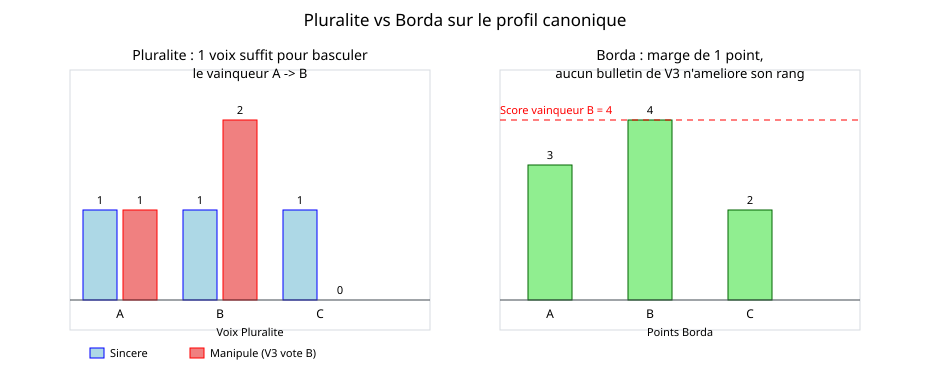


(122,15): warning CS0219: La variable 'topY' est assignée, mais sa valeur n'est jamais utilisée



In [6]:
// --- Exemple guide 3 : Borda est-elle egalement manipulable sur ce profil ? ---

static class BordaTool
{
    // Scores Borda : 2 points au rang 1, 1 au rang 2, 0 au rang 3.
    public static Dictionary<string, int> ScoresBorda(IReadOnlyList<List<string>> ballots)
    {
        var scores = new Dictionary<string, int>
        {
            ["A"] = 0,
            ["B"] = 0,
            ["C"] = 0
        };

        foreach (var ballot in ballots)
        {
            for (var rank = 0; rank < ballot.Count; rank++)
            {
                scores[ballot[rank]] += 2 - rank;
            }
        }

        return scores;
    }
}

var bordaVoter = 2;
var bordaPref = PROFILE[bordaVoter];
var sincereBordaWinner = SocialChoice.BordaWinner(PROFILE);
var sincereBordaRank = SocialChoice.RankOf(sincereBordaWinner, bordaPref);
Console.WriteLine($"Vainqueur Borda sincere : {sincereBordaWinner} (rang {sincereBordaRank} pour V{bordaVoter + 1})");
Console.WriteLine();

// Enumeration exhaustive des bulletins de V3
Console.WriteLine($"{"Bulletin V3",-25}{"Vainqueur Borda",-18}{"Rang V3",-10}{"Gain",-8}");
Console.WriteLine(new string('-', 65));
var bordaManipulations = new List<(List<string> Ballot, string Winner, int Rank)>();
foreach (var permutation in Ballots.Permutations("A", "B", "C"))
{
    var insincere = new List<string>(permutation);
    var ballots = PROFILE
        .Select((preference, index) => index == bordaVoter ? insincere : new List<string>(preference))
        .ToList();
    var winner = SocialChoice.BordaWinner(ballots);
    var newRank = SocialChoice.RankOf(winner, bordaPref);
    var gain = sincereBordaRank - newRank;
    var marker = gain > 0 ? "  <-- TEMOIN" : "";
    Console.WriteLine($"  {string.Join(", ", insincere),-23}{winner,-18}{newRank,-10}{gain,-8}{marker}");
    if (gain > 0)
    {
        bordaManipulations.Add((insincere, winner, newRank));
    }
}

Console.WriteLine();
if (bordaManipulations.Count > 0)
{
    Console.WriteLine($"Borda : {bordaManipulations.Count} temoin(s) de manipulation trouve(s).");
    foreach (var (insincere, winner, rank) in bordaManipulations)
    {
        Console.WriteLine($"  V{bordaVoter + 1} vote {string.Join(", ", insincere)} -> {winner} (rang {rank} pour V{bordaVoter + 1})");
    }
}
else
{
    Console.WriteLine("Borda : AUCUN temoin de manipulation pour V3 sur ce profil.");
    Console.WriteLine("Les scores Borda sinceres sont :");
    var scores = BordaTool.ScoresBorda(PROFILE);
    foreach (var (alternative, score) in scores.OrderByDescending(entry => entry.Value))
    {
        Console.WriteLine($"  {alternative} = {score} points");
    }

    // Conclusion derivee (PAS de chaine en dur)
    var ranked = scores.OrderByDescending(entry => entry.Value).ToList();
    var top1 = ranked[0].Key;
    var score1 = ranked[0].Value;
    var top2 = ranked[1].Key;
    var score2 = ranked[1].Value;
    var margin = score1 - score2;
    var points = margin == 1 ? "point" : "points";
    Console.WriteLine($"  -> {top1} devance {top2} de {margin} {points} ({score1} vs {score2}).");
}

// Le meme temoin est-il present sous Pluralite ? (verification locale, ordre d'execution independent)
var pluralityManipulable = false;
foreach (var voter in Enumerable.Range(0, PROFILE.Count))
{
    var sincerePlurality = SocialChoice.PluralityWinner(PROFILE);
    var sincereRank = SocialChoice.RankOf(sincerePlurality, PROFILE[voter]);
    foreach (var permutation in Ballots.Permutations("A", "B", "C"))
    {
        var insincere = new List<string>(permutation);
        var ballots = PROFILE
            .Select((preference, index) => index == voter ? insincere : new List<string>(preference))
            .ToList();
        var winner = SocialChoice.PluralityWinner(ballots);
        if (sincereRank - SocialChoice.RankOf(winner, PROFILE[voter]) > 0)
        {
            pluralityManipulable = true;
        }
    }
}

Console.WriteLine();
Console.WriteLine("=== Comparaison synthetique ===");
Console.WriteLine($"Pluralite : {(pluralityManipulable ? "MANIPULABLE" : "NON MANIPULABLE")} (exploitation du tiebreak)");
Console.WriteLine($"Borda     : {(bordaManipulations.Count > 0 ? "MANIPULABLE par V3" : "NON MANIPULABLE par V3")} (sur ce profil precis)");
Console.WriteLine();
Console.WriteLine("Conclusion nuancee : pour V3, Pluralite est manipulable ici et Borda ne l'est pas ;");
Console.WriteLine("Borda reste manipulable par d'autres votants ou profils (Gibbard-Satterthwaite) -");
Console.WriteLine("le profil didactique choisi ici protege V3 par arithmetique : C plafonne a 2 points quand A ou B atteint au moins 4 (bulletins fixes de V1 et V2).");
Console.WriteLine("Sur un profil ou les marges sont plus serrees, Borda admet aussi des temoins.");

// Visualisation comparative (SVG type, deux panneaux)
string DrawPluralityPanel(int x0)
{
    var labels = new[] { "A", "B", "C" };
    var sincereVotes = new[] { 1, 1, 1 };
    var manipulatedVotes = new[] { 1, 2, 0 };
    const int baseY = 300;
    const int topY = 100;
    const int plotHeight = 180;
    const int barWidth = 34;
    var svg = new StringBuilder();
    svg.Append("<rect x='70' y='70' width='360' height='260' fill='none' stroke='#d7dce1'/>");
    svg.Append($"<text x='250' y='60' text-anchor='middle' font-family='sans-serif' font-size='14'>Pluralite : 1 voix suffit pour basculer</text>");
    svg.Append($"<text x='250' y='78' text-anchor='middle' font-family='sans-serif' font-size='13'>le vainqueur A -&gt; B</text>");
    for (var index = 0; index < labels.Length; index++)
    {
        var x = 120 + index * 100;
        var h1 = sincereVotes[index] * (plotHeight / 2.0);
        var h2 = manipulatedVotes[index] * (plotHeight / 2.0);
        svg.Append($"<rect x='{x - barWidth - 3}' y='{baseY - h1:F0}' width='{barWidth}' height='{h1:F0}' fill='lightblue' stroke='blue'/>");
        svg.Append($"<rect x='{x + 3}' y='{baseY - h2:F0}' width='{barWidth}' height='{h2:F0}' fill='lightcoral' stroke='red'/>");
        svg.Append($"<text x='{x - barWidth / 2 - 3}' y='{baseY - h1 - 6:F0}' text-anchor='middle' font-family='sans-serif' font-size='11'>{sincereVotes[index]}</text>");
        svg.Append($"<text x='{x + barWidth / 2 + 3}' y='{baseY - h2 - 6:F0}' text-anchor='middle' font-family='sans-serif' font-size='11'>{manipulatedVotes[index]}</text>");
        svg.Append($"<text x='{x}' y='{baseY + 18}' text-anchor='middle' font-family='sans-serif' font-size='12'>{labels[index]}</text>");
    }
    svg.Append($"<line x1='70' y1='{baseY}' x2='430' y2='{baseY}' stroke='#414a52'/>");
    svg.Append($"<text x='250' y='{baseY + 36}' text-anchor='middle' font-family='sans-serif' font-size='11'>Voix Pluralite</text>");
    svg.Append("<rect x='90' y='348' width='14' height='10' fill='lightblue' stroke='blue'/><text x='110' y='357' font-family='sans-serif' font-size='11'>Sincere</text>");
    svg.Append("<rect x='190' y='348' width='14' height='10' fill='lightcoral' stroke='red'/><text x='210' y='357' font-family='sans-serif' font-size='11'>Manipule (V3 vote B)</text>");
    return svg.ToString();
}

string DrawBordaPanel(int x0)
{
    var labels = new[] { "A", "B", "C" };
    var bordaScores = BordaTool.ScoresBorda(PROFILE);
    var values = new[] { bordaScores["A"], bordaScores["B"], bordaScores["C"] };
    var maxValue = Math.Max(1, values.Max());
    const int baseY = 300;
    const int plotHeight = 180;
    const int barWidth = 44;
    var ranked = bordaScores.OrderByDescending(entry => entry.Value).ToList();
    var winnerAlternative = ranked[0].Key;
    var winnerScore = ranked[0].Value;
    var runnerScore = ranked[1].Value;
    var margin = winnerScore - runnerScore;
    var svg = new StringBuilder();
    svg.Append("<rect x='500' y='70' width='360' height='260' fill='none' stroke='#d7dce1'/>");
    svg.Append($"<text x='680' y='60' text-anchor='middle' font-family='sans-serif' font-size='14'>Borda : marge de {margin} {(margin > 1 ? "points" : "point")},</text>");
    svg.Append("<text x='680' y='78' text-anchor='middle' font-family='sans-serif' font-size='13'>aucun bulletin de V3 n'ameliore son rang</text>");
    for (var index = 0; index < labels.Length; index++)
    {
        var x = 550 + index * 100;
        var height = values[index] * (plotHeight / (double)maxValue);
        svg.Append($"<rect x='{x - barWidth / 2}' y='{baseY - height:F0}' width='{barWidth}' height='{height:F0}' fill='lightgreen' stroke='darkgreen'/>");
        svg.Append($"<text x='{x}' y='{baseY - height - 6:F0}' text-anchor='middle' font-family='sans-serif' font-size='11'>{values[index]}</text>");
        svg.Append($"<text x='{x}' y='{baseY + 18}' text-anchor='middle' font-family='sans-serif' font-size='12'>{labels[index]}</text>");
    }
    var winnerY = baseY - winnerScore * (plotHeight / (double)maxValue);
    svg.Append($"<line x1='500' y1='{winnerY:F0}' x2='860' y2='{winnerY:F0}' stroke='red' stroke-dasharray='6 5'/>");
    svg.Append($"<text x='500' y='{winnerY - 6:F0}' font-family='sans-serif' font-size='11' fill='red'>Score vainqueur {winnerAlternative} = {winnerScore}</text>");
    svg.Append($"<line x1='500' y1='{baseY}' x2='860' y2='{baseY}' stroke='#414a52'/>");
    svg.Append($"<text x='680' y='{baseY + 36}' text-anchor='middle' font-family='sans-serif' font-size='11'>Points Borda</text>");
    return svg.ToString();
}

var comparisonSvg = new StringBuilder();
comparisonSvg.Append("<svg xmlns='http://www.w3.org/2000/svg' role='img' aria-label='Comparaison Pluralite et Borda sur le profil canonique' viewBox='0 0 930 380' width='930' height='380'>");
comparisonSvg.Append("<rect width='100%' height='100%' fill='white'/>");
comparisonSvg.Append("<text x='465' y='26' text-anchor='middle' font-family='sans-serif' font-size='17'>Pluralite vs Borda sur le profil canonique</text>");
comparisonSvg.Append(DrawPluralityPanel(40));
comparisonSvg.Append(DrawBordaPanel(470));
comparisonSvg.Append("</svg>");

display(new PlotSvg(comparisonSvg.ToString()));

Sur ce profil, Borda n'est pas manipulable par V3 : aucun bulletin ne fait gagner un candidat que V3 prefere a B, qui a 4 points contre 3 pour A et 2 pour C (scores imprimes par la cellule ci-dessus). La comparaison donne donc, pour V3, Pluralite manipulable et Borda non manipulable sur ce profil precis. Attention au perimetre : ce balayage ne teste que V3 — sur ce MEME profil, V1 peut manipuler Borda (en declarant A>C>B au lieu de A>B>C, les scores deviennent A=3, B=3, C=3 et le departage alphabetique elit A au lieu de B, ce qui ameliore le rang de A pour V1 de 2 a 1). La fragilite du tiebreak rend Pluralite facilement manipulable ici. Pourquoi V3 est-il protege sous Borda sur ce profil ? Avant meme le bulletin de V3, les bulletins fixes de V1 et V2 distribuent 6 points : A=3, B=3, C=0. Quel que soit le bulletin de V3, C (son prefere) plafonne a 2 points tandis que A ou B atteint au moins 4 : C ne gagne jamais, et les six bulletins de V3 font gagner A ou B — jamais un resultat meilleur pour lui que B au sincere (rang 2). Borda reste structurellement manipulable (V1 ci-dessus, ou d'autres profils). L'exercice 3 cherche un profil a 3 votants ou Borda l'est.

### Exercice 3 : un profil a 3 votants ou Borda est manipulable

**Contexte.** L'exemple guide 3 ne trouve aucun temoin de Borda sur son profil. Le theoreme de Gibbard-Satterthwaite dit qu'il existe des profils ou une regle non dictatoriale sur 3 alternatives est manipulable : reste a exhiber un tel profil pour Borda, avec 3 votants.

**Objectif.** Parmi les profils a 3 votants sur `A`, `B`, `C`, trouver un profil, un votant et un bulletin insincere tels que le votant obtienne, avec ce bulletin, un vainqueur Borda strictement meilleur pour lui.

**Indices.**
- `Ballots.Permutations("A", "B", "C")` donne les 6 bulletins possibles ; `BordaSearch.Profils3Votants()` enumere les profils a 3 votants (equivalent de `itertools.product`).
- `SocialChoice.RankOf` donne le rang d'un candidat dans une preference, et `SocialChoice.BordaWinner` le vainqueur d'un ensemble de bulletins.
- Le departage de `SocialChoice.BordaWinner` est alphabetique. Un profil dont le vainqueur apres manipulation est unique evite de dependre de ce departage.

**Critere de verification.** La cellule suivante affiche le profil trouve et deux booleens. Le profil est accepte si les deux valent `True`.

In [7]:
// --- Exercice 3 : chercher un profil a 3 votants ou Borda est manipulable ---
static class BordaSearch
{
    // Scores Borda : 2 points au rang 1, 1 au rang 2, 0 au rang 3 (delegue a BordaTool).
    public static Dictionary<string, int> ScoresBorda(IReadOnlyList<List<string>> ballots)
    {
        return BordaTool.ScoresBorda(ballots);
    }

    // Les 6 bulletins possibles sur A, B, C.
    public static IEnumerable<List<string>> Bulletins()
    {
        return Ballots.Permutations("A", "B", "C");
    }

    // Les profils a 3 votants (equivalent de itertools.product sur les 6 bulletins).
    public static IEnumerable<List<List<string>>> Profils3Votants()
    {
        foreach (var premier in Bulletins())
        foreach (var deuxieme in Bulletins())
        foreach (var troisieme in Bulletins())
        {
            yield return new List<List<string>>
            {
                new List<string>(premier),
                new List<string>(deuxieme),
                new List<string>(troisieme)
            };
        }
    }

    public static (List<List<string>> Profil, int Voter, List<string> Bulletin)? ChercheProfilBordaManipulable()
    {
        // TODO etudiant : enumerer les profils, puis les votants et leurs bulletins
        // (Profils3Votants(), puis Bulletins()), et renvoyer le premier couple
        // (profil, votant, bulletin) ou le vainqueur Borda est strictement meilleur
        // pour ce votant que le vainqueur sincere.
        return null; // TODO etudiant
    }
}

var resultat = BordaSearch.ChercheProfilBordaManipulable();
if (resultat is null)
{
    Console.WriteLine("Exercice a completer");
}
else
{
    var (profil, votant, bulletin) = resultat.Value;
    var apres = profil.Select((preference, index) => index == votant ? bulletin : new List<string>(preference)).ToList();
    var s = BordaSearch.ScoresBorda(apres);
    var maxScore = s.Values.Max();
    var ameliore = SocialChoice.RankOf(SocialChoice.BordaWinner(apres), profil[votant])
        < SocialChoice.RankOf(SocialChoice.BordaWinner(profil), profil[votant]);
    var unique = s.Count(entry => entry.Value == maxScore) == 1;
    Console.WriteLine($"Profil : {string.Join(" | ", profil.Select(preference => string.Join(", ", preference)))}");
    Console.WriteLine($"V{votant + 1} vote {string.Join(", ", bulletin)} : amelioration = {ameliore}, vainqueur unique apres manipulation = {unique}");
}

Exercice a completer


## 5. Conclusion : ce que le temoin prouve

**Trois resultats a retenir** :

1. **Le temoin est constructif** - sur le profil canonique de Satterthwaite, un electeur (V3) peut exhiber un bulletin *concret* (`B > A > C` au lieu de `C > B > A`) qui ameliore son sort sous Pluralite (rang 3 -> rang 2). La preuve d'exploitation n'est pas abstraite : c'est un objet qu'on tient en main.

2. **La regle de vote n'est pas une propriete abstraite** - Pluralite se manipule par exploitation du tiebreak (1 voix suffit), Borda se manipule en fabriquant un vainqueur prefere : ici V3 ne le peut pas parce que C plafonne a 2 points quand A ou B atteint au moins 4 (arithmetique de la section 4) — l'ecart sincere B=4 vs A=3 n'est que le symptome de cette impossibilite. Le choix d'une regle est un choix sur les **chemins de manipulation** qu'on rend possibles.

3. **Gibbard-Satterthwaite est structurel** - pour *toute* regle surjective et non dictatoriale avec >=3 alternatives, il *existe* un profil manipulable : le theoreme ne dit pas que tout profil l'est : le profil choisi ici ne fait qu'*exhiber* un temoin pour Pluralite, et le theoreme dit qu'on en trouverait un pour Borda aussi sur un profil approprie. C'est la portee universelle du resultat.

**Limites du modele** : ce profil est minimal (3 electeurs, 3 alternatives). La litterature etend le resultat a N electeurs et M alternatives, avec des bornes sur le nombre de manipulations selon la structure de la regle (e.g. regles a seuil, regles a veto, regles positionnelles). La complexite de la recherche de manipulation est elle-meme un objet d'etude : certaines regles sont *strategyproof* sur des domaines restreints (e.g. preferences unimodales pour la regle du vote majoritaire a 2 tours), mais pas sur le domaine general.

**Lien avec la science politique** : la manipulation par bulletin insincere est observee empiriquement dans les elections reelles. Le resultat theorique explique pourquoi : il serait etonnant que les electeurs *ne* trouvent pas de manipulation, puisque le theoreme garantit qu'il en existe. Les parades institutionnelles (bulletin secret, depouillement public, education civique) reduisent l'incitation sans elever la barriere computationnelle - c'est la these de Riker (1982) sur l'heresthetic.
## References bibliographiques

- Gibbard, A. (1973). Manipulation of Voting Schemes: A General Result. Econometrica 41(4):587-601.
- Satterthwaite, M.A. (1975). Strategy-proofness and Arrow's Conditions: Existence and Correspondence Theorems for Voting Procedures and Social Welfare Functions. Journal of Economic Theory 10(2):187-217.
- Brandt, F., Conitzer, V., Endriss, U., Lang, J., Procaccia, A. D. (2016). *Handbook of Computational Social Choice*. Cambridge University Press. ISBN 978-1-107-06043-2. **Ancrage ch. 6, §6.2 « Gibbard-Satterthwaite and Its Implications » (Conitzer et Walsh)** — la barriere calculatoire a la manipulation comme angle d'attaque des resultats d'impossibilite : ou la complexite de trouver une manipulation profitable protege en pratique la procedure. Source biblio cluster : `G:\Mon Drive\MyIA\IA\Bibliographie IA\GameTheory\Social Choice, Voting and Welfare\2016 - Brandt Conitzer Endriss Lang - Handbook of Computational Social Choice.pdf`.

## À retenir

| Leçon | Mesure dans ce carnet |
|---|---|
| Un seul profil, trois vainqueurs : c'est le tiebreak qui décide | `Tiebreak A>B>C : vainqueur = A`, `Tiebreak B>A>C : vainqueur = B`, `Tiebreak C>B>A : vainqueur = C` |
| Deux règles usuelles divergent sur ce même profil | `Vainqueur Pluralite sincere : A` contre `Vainqueur Borda sincere : B` (`-> Pluralite A, Borda B : divergent.`) |
| La fragilité de la règle se lit dans le rang du gagnant | `Rang de A pour V3 : 3 (dernier)` — le vainqueur de la pluralité est le **pire** choix de V3 |
| Le témoin de manipulation est un objet, pas une intuition | `V3 manipule : B, A, C` puis `Vainqueur manipule : B (rang 2 pour V3)` et `GAIN : rang 3 -> rang 2` |
| L'impossibilite pour un votant se demontre par l'arithmetique des scores | Avant le bulletin de V3, A et B ont deja 3 points chacun et C plafonne a 2 : `Borda : AUCUN temoin de manipulation pour V3 sur ce profil` — l'ecart sincere `B = 4 points` contre `A = 3 points` n'en est que le symptome |
| L'absence de temoin pour UN votant n'est pas une immunite | `Pluralite : MANIPULABLE (exploitation du tiebreak)` et `Borda : NON MANIPULABLE par V3 (sur ce profil precis)` ; V1, lui, manipule Borda sur ce meme profil (voir section 4) |


## Vérifiez votre compréhension

**Question 1 — Sur le profil de ce carnet, V3 peut-il améliorer son rang sous Borda ?**

La section 4 affiche le tableau des six bulletins possibles pour V3, avec des gains de `-1` ou `0`, puis la ligne `Borda : AUCUN temoin de manipulation pour V3 sur ce profil`.

<details><summary>Réponse</summary>

Non pour V3, sur **ce** profil (mais oui pour V1 : voir le contre-exemple de la section 4). Les six bulletins possibles de V3 sont tous évalués, et aucun ne fait gagner à V3 un candidat qu'il préfère à B : les gains sont `-1` ou `0`, jamais positif. La raison est donnée par les scores : `B = 4 points`, `A = 3 points`, `C = 2 points`, donc `B devance A de 1 point`. La marge initiale n'est que le symptome : la vraie raison est arithmetique — avant le bulletin de V3, A et B ont deja 3 points chacun et C plafonne a 2, donc C ne peut jamais gagner (section 4). Ce que ce résultat ne dit pas : que Borda est strategyproof. Le carnet le dit lui-même — `Pluralite : MANIPULABLE (exploitation du tiebreak)`, `Borda : NON MANIPULABLE par V3 (sur ce profil precis)` — et l'exercice 3 demande justement le profil où Borda cesse d'être protégé. Et le carnet montre aussi que la protection ne vaut que pour V3 : V1 améliore son rang sous Borda sur ce même profil (section 4).

</details>

**Question 2 — Pourquoi la fragilité attribuée ici à la règle porte-t-elle sur le tiebreak plutôt que sur la règle elle-même ?**

La section 2 affiche trois vainqueurs pour un seul profil : `Tiebreak A>B>C : vainqueur = A`, `Tiebreak B>A>C : vainqueur = B`, `Tiebreak C>B>A : vainqueur = C`, tandis que la même section affiche `Borda sincere : vainqueur = B (deterministe, pas de tiebreak)`.

<details><summary>Réponse</summary>

Parce qu'au **sincere**, le vainqueur tient tout entier a l'**ordre arbitraire des egalites** : trois ordres de departage differents donnent trois vainqueurs differents sur un profil inchange — rien dans les preferences ne decide, c'est la convention qui decide. Le temoin, lui, combine deux leviers : le bulletin insincere modifie le depouillement (B passe a 2 voix contre 1 et gagne **sans egalite**), et c'est le departage qui avait elu A au sincere. La fragilite du departage est ce qui rend le gain accessible ici, pas le seul mecanisme du gain. Borda, sur le même profil, n'a pas besoin de cette convention et rend un vainqueur unique, déterministe. Sur CE profil, la pluralite offre un temoin immediat quand Borda n'en offre aucun pour V3 — sans que cela mesure une difficulte generale de manipulation. Le mecanisme du temoin est d'ailleurs explicite : `V3 manipule : B, A, C` retire une voix a C pour la donner a B, qui gagne alors seul (2 voix contre 1) — sans departage cette fois — et fait passer V3 du rang 3 au rang 2.

</details>


## Pour aller plus loin

- [Index de la sous-série SocialChoice](README.md) — le fil de la sous-série et ce que chaque carnet y ajoute.
- [Index de la série GameTheory](../README.md) — la place de l'impossibilité de manipulation parmi les autres structures de la théorie des jeux.

Les carnets voisins sont cités en prose, sans lien. `ChoixSocial-01-Arrow-Impossibility-Theorem` pose le cadre axiomatique qui précède celui-ci : l'impossibilité de manipulation y est l'aboutissement d'une famille de conditions, alors que ce carnet en montre le mécanisme sur un profil unique. `ChoixSocial-06-Mobius-Aggregation-Pouvoir-Manipulation` attaque le même objet par l'agrégation de Möbius et le pouvoir de manipulation, et `ChoixSocial-10-Manipulation-Strategique-MultiWinner` le mesure sur un espace exhaustif de 216 profils, avec les règles à comité. `ChoixSocial-09-Committees-STV-Monroe-ChamberlinCourant` complète le tableau avec les règles de sélection à plusieurs sièges.

La suite du travail est déjà posée dans le carnet : l'exercice 3 demande le profil à trois votants sur lequel Borda admet un témoin, et l'exercice 1 le profil à quatre votants où c'est le tiebreak seul qui décide du vainqueur.

> Carnet issu de l'EPIC #26534 (parité C# de la série SocialChoice, jumeau Python `ChoixSocial-05-Gibbard-Satterthwaite-Python.ipynb`).
